In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score

In [2]:
data = pd.read_csv('chapter3_task_data.csv')
data.head()

,pay1,pay2,y
0,2.946794,0.057996,1
1,10.202126,8.798162,0
2,13.962240,89.794215,1
3,106.090589,45.969875,1
4,80.713481,112.575403,1


In [3]:
mask = data.loc[:,'y']==1
mask = ~mask

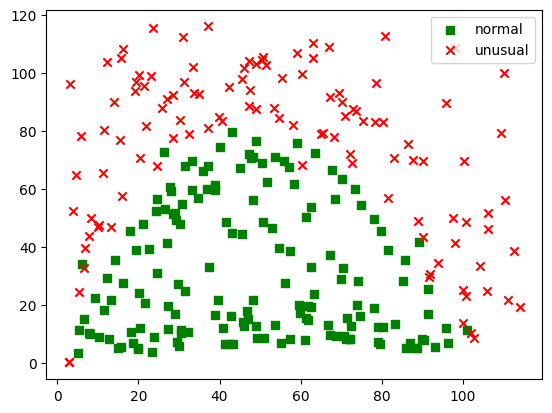

In [4]:
fig1 = plt.figure()
normal = plt.scatter(data.loc[:,'pay1'][mask],data.loc[:,'pay2'][mask],marker='s',color='green')
unusual = plt.scatter(data.loc[:,'pay1'][~mask],data.loc[:,'pay2'][~mask],marker='x',color='red')
plt.legend((normal,unusual),('normal','unusual'))
plt.show()

In [5]:
def new_x2(x1):
    a = theta4
    b = theta5*x1+theta2
    c = theta0+theta1*x1+theta3*x1*x1
    pos_x2_new = (-b+np.sqrt(b**2-4*a*c))/(2*a)
    nei_x2_new = (-b-np.sqrt(b**2-4*a*c))/(2*a)
    return pos_x2_new,nei_x2_new

In [6]:
x1 = data.loc[:,'pay1']
x2 = data.loc[:,'pay2']
y = data.loc[:,'y']
x_new_dic = {'x1':x1,'x2':x2,'x1_2':x1**2,'x2_2':x2**2,'x1_x2':x1*x2}
x_new = pd.DataFrame(x_new_dic)
lr = LogisticRegression()
lr.fit(x_new,y)

/Users/liuyide/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [7]:
y_predict = lr.predict(x_new)
ase = accuracy_score(y,y_predict)
ase

0.967032967032967

In [8]:
x1 = 70
x2 = 15
x_test_dic = {'x1':x1,'x2':x2,'x1_2':x1**2,'x2_2':x2**2,'x1_x2':x1*x2}
x_test = pd.DataFrame(x_test_dic,index=[0])
y_predict_test = lr.predict(x_test)
print('normal' if y_predict_test[0] else 'unusual')

unusual


/Users/liuyide/anaconda3/envs/ai_tec/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


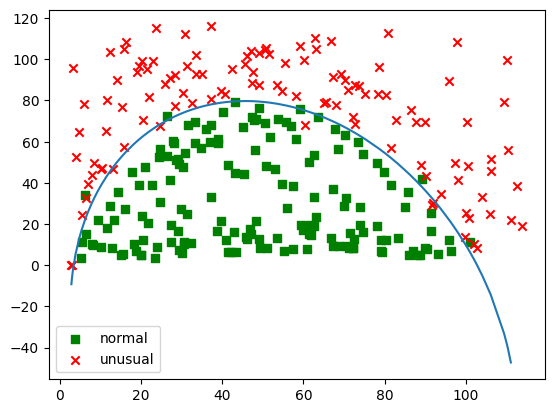

In [9]:
theta0 = lr.intercept_[0]
theta1,theta2,theta3,theta4,theta5 = lr.coef_[0]
x1 = data.loc[:,'pay1'].sort_values()
pos_x2_new = new_x2(x1)[0]
fig2 = plt.figure()
normal = plt.scatter(data.loc[:,'pay1'][mask],data.loc[:,'pay2'][mask],marker='s',color='green')
unusual = plt.scatter(data.loc[:,'pay1'][~mask],data.loc[:,'pay2'][~mask],marker='x',color='red')
plt.legend((normal,unusual),('normal','unusual'))
plt.plot(x1,pos_x2_new)
plt.show()